<a href="https://colab.research.google.com/github/jasminealyaa1212/PCD-Assignment-3/blob/main/PCD__Assignment03_558659_Jasmine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Digital Image Processing Assignment 3**

Mounted at /content/drive
Otsu threshold: 163


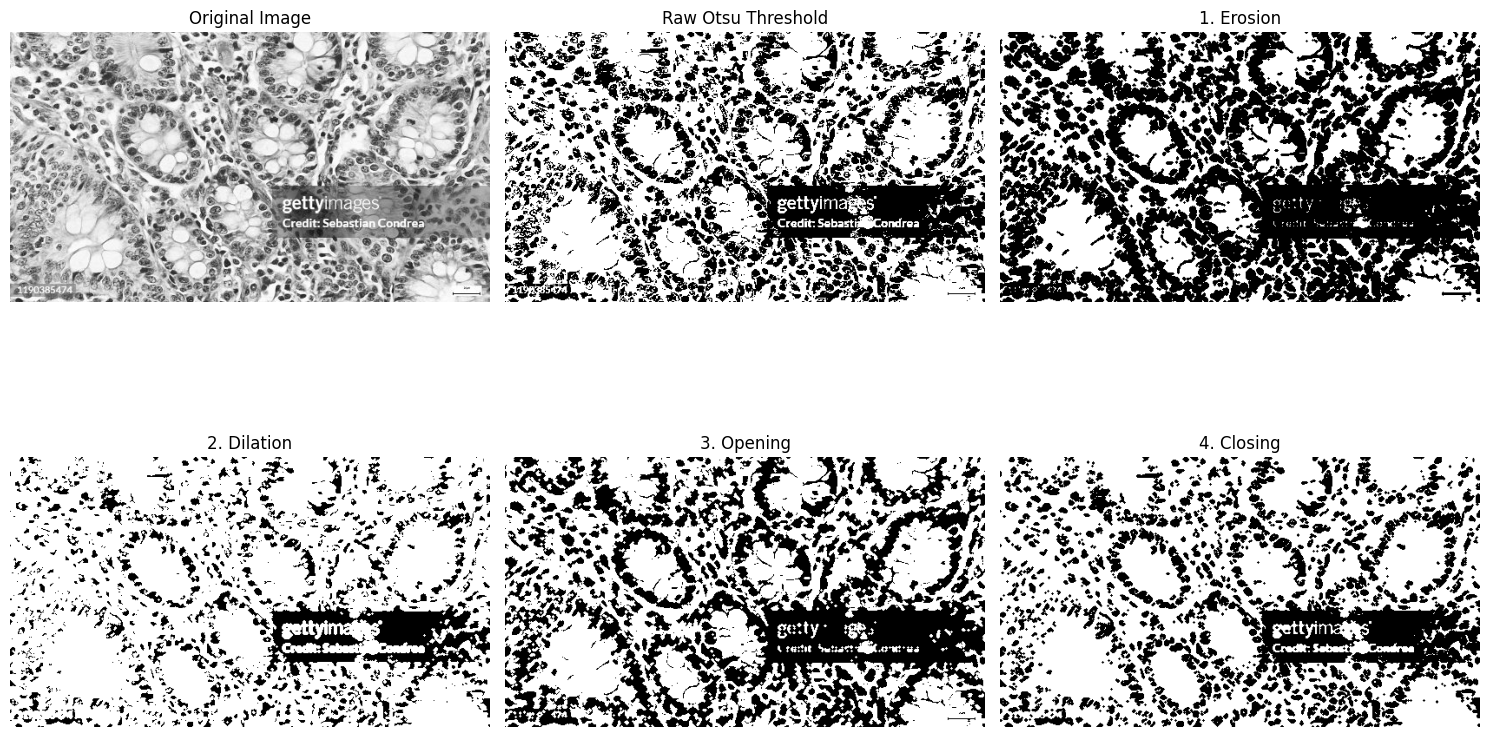

In [23]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/semester 3/Digital Image Processing/Assignment 3/pancreas.jpg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

def otsu_threshold(image):
    hist = np.zeros(256)
    for v in image.ravel():
        hist[v] += 1

    total = image.size
    sum_all = sum(i * hist[i] for i in range(256))

    count_dark, sum_dark = 0, 0
    best_score, best_t = 0, 0

    for t in range(256):
        count_dark += hist[t]
        count_bright = total - count_dark
        if count_dark == 0 or count_bright == 0:
            continue

        sum_dark += t * hist[t]
        mean_dark = sum_dark / count_dark
        mean_bright = (sum_all - sum_dark) / count_bright

        score = count_dark * count_bright * (mean_dark - mean_bright) ** 2

        if score > best_score:
            best_score, best_t = score, t

    return best_t

threshold = otsu_threshold(img)
raw_segmented = ((img > threshold) * 255).astype(np.uint8)

kernel = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

def erode(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    slices = [
        padded[i:i+h, j:j+w]
        for i in range(kh) for j in range(kw)
        if kernel[i, j] == 1
    ]
    return np.minimum.reduce(slices)

def dilate(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    slices = [
        padded[i:i+h, j:j+w]
        for i in range(kh) for j in range(kw)
        if kernel[i, j] == 1
    ]
    return np.maximum.reduce(slices)

def opening(image, kernel):
    return dilate(erode(image, kernel), kernel)

def closing(image, kernel):
    return erode(dilate(image, kernel), kernel)

eroded = erode(raw_segmented, kernel)
dilated = dilate(raw_segmented, kernel)
opened = opening(raw_segmented, kernel)
closed = closing(raw_segmented, kernel)


images = [img, raw_segmented, eroded, dilated, opened, closed]
titles = [
    'Original Image',
    'Raw Otsu Threshold',
    '1. Erosion',
    '2. Dilation',
    '3. Opening',
    '4. Closing'
]
print('Otsu threshold:', threshold)
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Mounted at /content/drive
Otsu threshold: 143


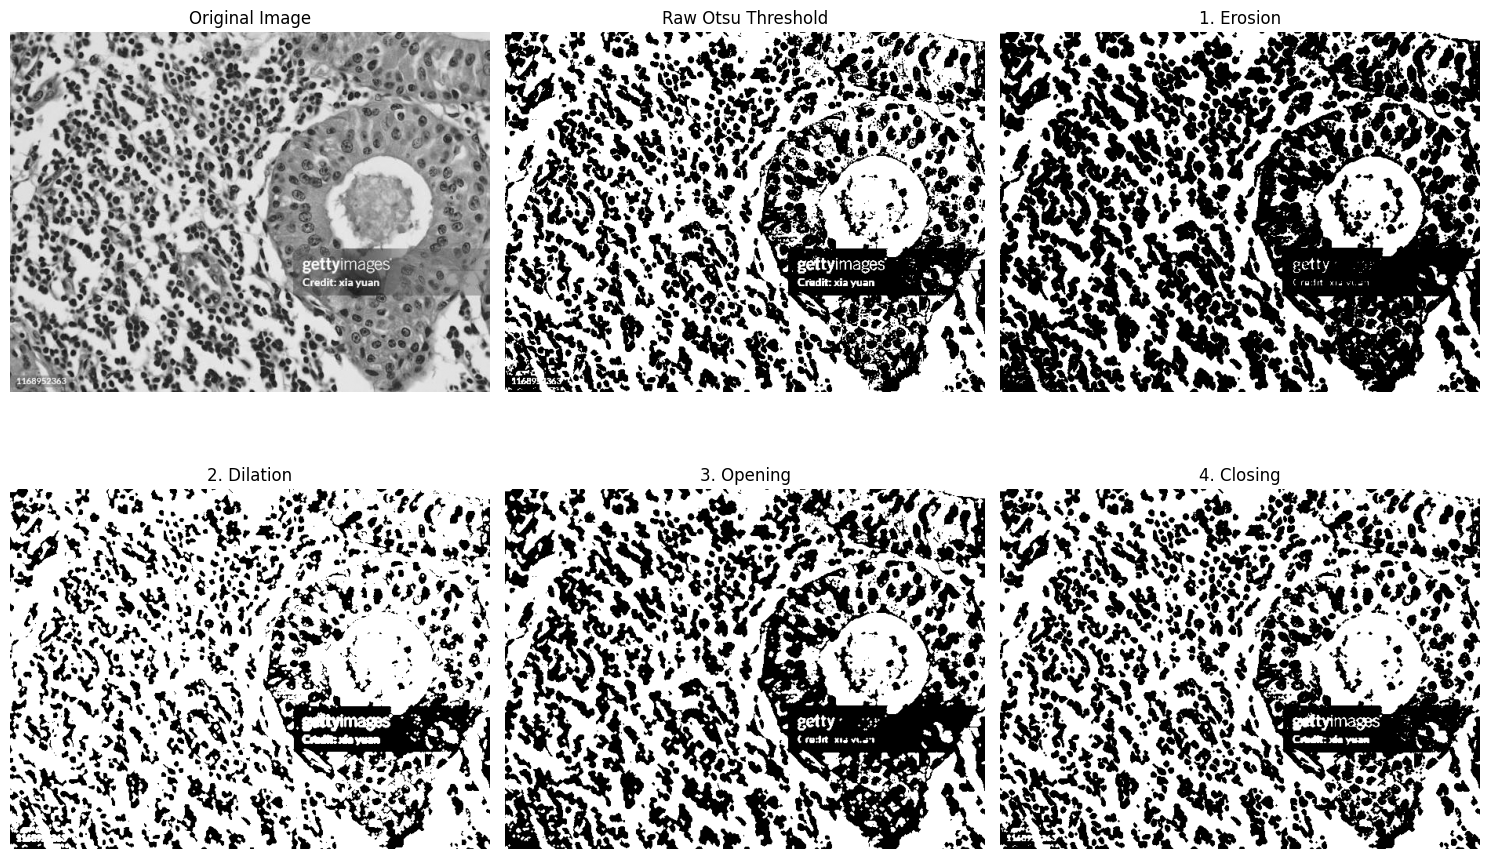

In [24]:
drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/semester 3/Digital Image Processing/Assignment 3/cancer.jpg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

threshold = otsu_threshold(img)
raw_segmented = ((img > threshold) * 255).astype(np.uint8)

eroded = erode(raw_segmented, kernel)
dilated = dilate(raw_segmented, kernel)
opened = opening(raw_segmented, kernel)
closed = closing(raw_segmented, kernel)

images = [img, raw_segmented, eroded, dilated, opened, closed]
titles = [
    'Original Image',
    'Raw Otsu Threshold',
    '1. Erosion',
    '2. Dilation',
    '3. Opening',
    '4. Closing'
]
print('Otsu threshold:', threshold)
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Mounted at /content/drive
Otsu threshold: 125


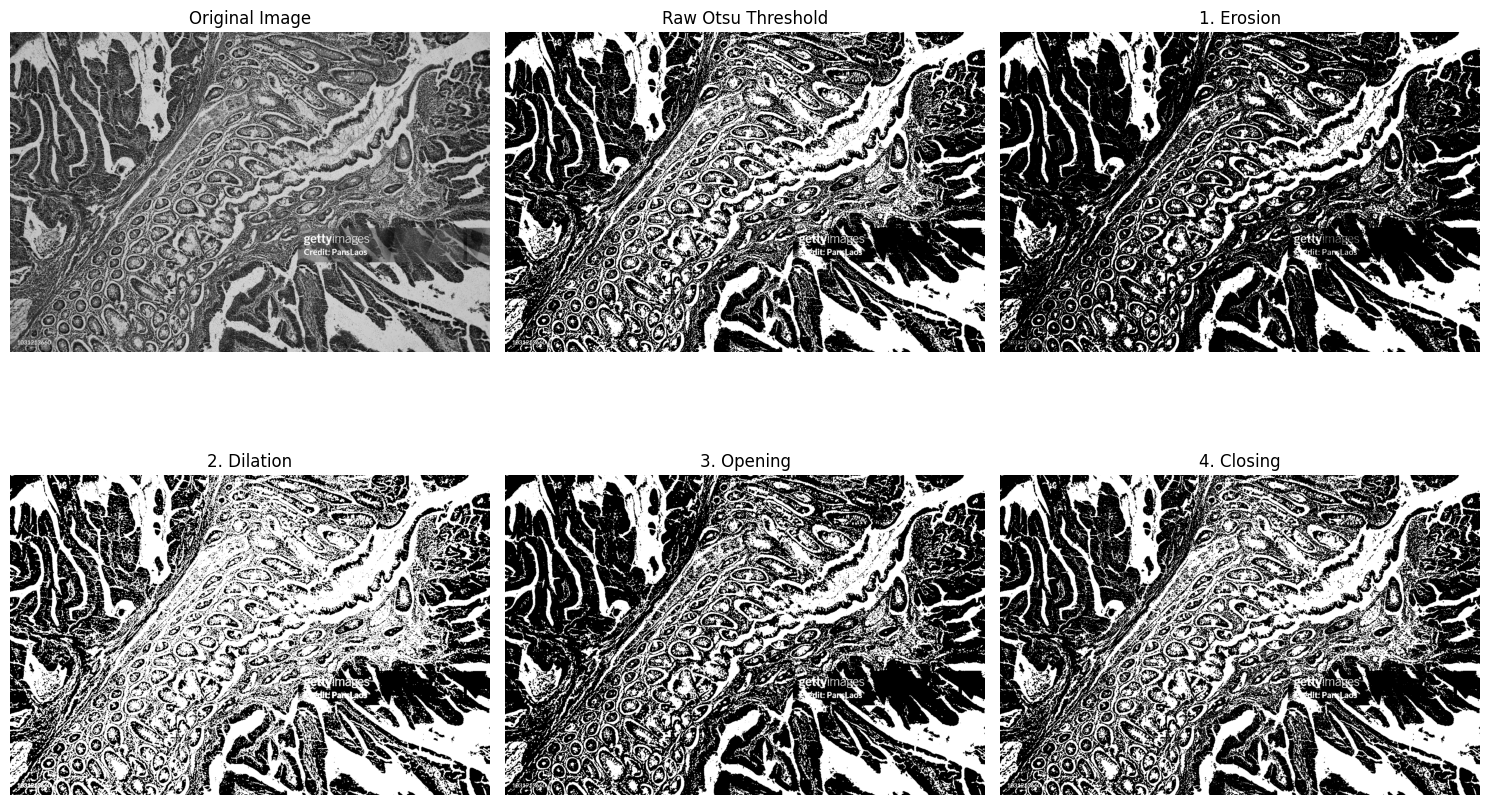

In [25]:
drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/semester 3/Digital Image Processing/Assignment 3/tumor.jpg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

threshold = otsu_threshold(img)
raw_segmented = ((img > threshold) * 255).astype(np.uint8)

eroded = erode(raw_segmented, kernel)
dilated = dilate(raw_segmented, kernel)
opened = opening(raw_segmented, kernel)
closed = closing(raw_segmented, kernel)

images = [img, raw_segmented, eroded, dilated, opened, closed]
titles = [
    'Original Image',
    'Raw Otsu Threshold',
    '1. Erosion',
    '2. Dilation',
    '3. Opening',
    '4. Closing'
]
print('Otsu threshold:', threshold)
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

Mounted at /content/drive
Otsu threshold: 146


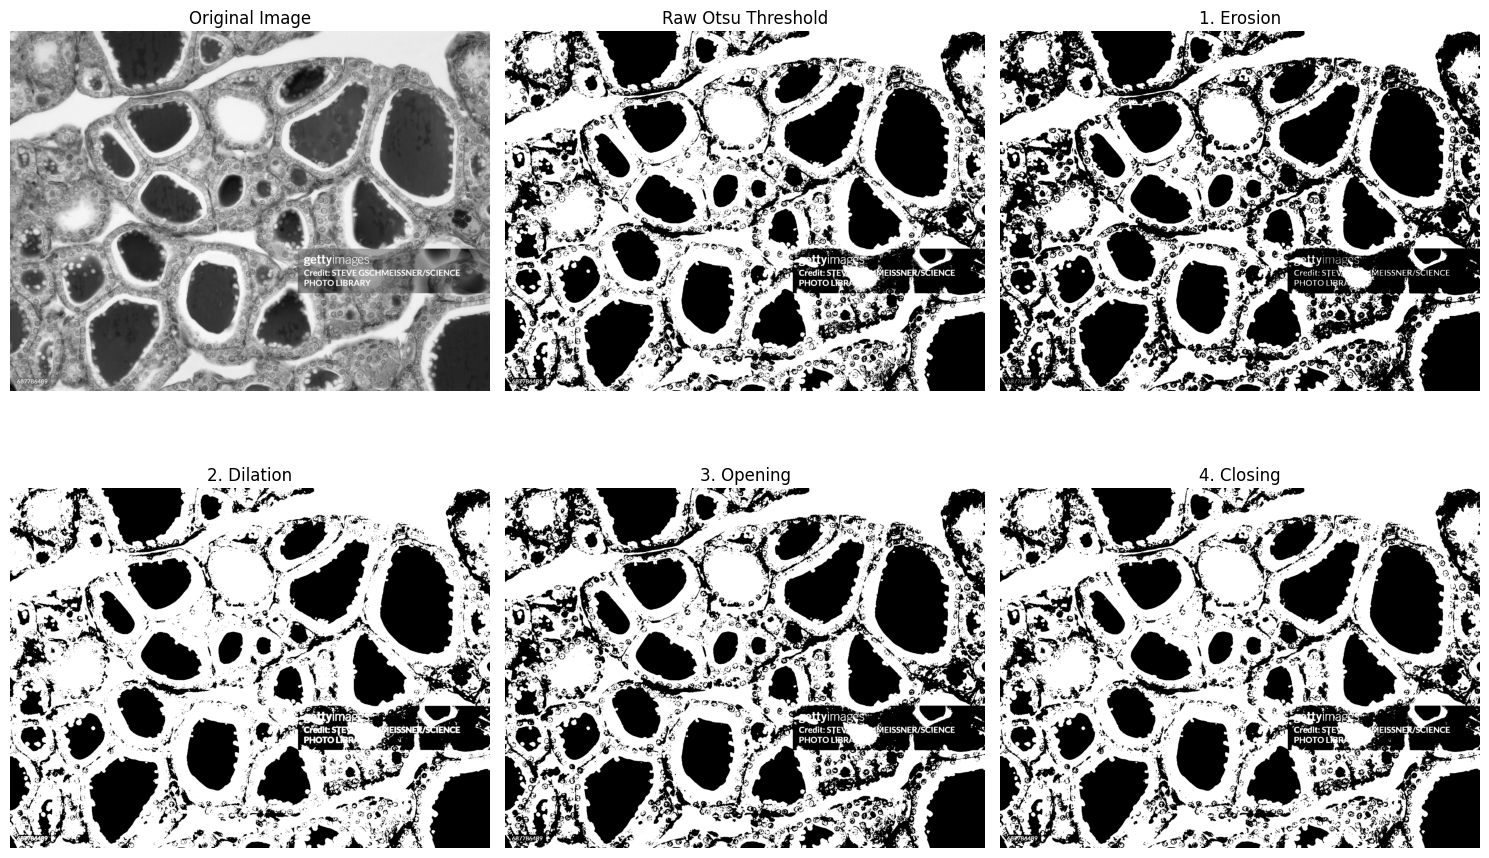

In [26]:
drive.mount('/content/drive', force_remount=True)

image_path = '/content/drive/MyDrive/semester 3/Digital Image Processing/Assignment 3/thyroid.jpg'
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

threshold = otsu_threshold(img)
raw_segmented = ((img > threshold) * 255).astype(np.uint8)

eroded = erode(raw_segmented, kernel)
dilated = dilate(raw_segmented, kernel)
opened = opening(raw_segmented, kernel)
closed = closing(raw_segmented, kernel)

images = [img, raw_segmented, eroded, dilated, opened, closed]
titles = [
    'Original Image',
    'Raw Otsu Threshold',
    '1. Erosion',
    '2. Dilation',
    '3. Opening',
    '4. Closing'
]
print('Otsu threshold:', threshold)
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()